# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv('Mall_Customers.csv')

print('Jumlah baris dan kolom:', df.shape)
display(df.head())

print('\nTipe data:')
display(df.dtypes.to_frame('dtype'))

print('\nStatistik deskriptif:')
display(df.describe().round(2))

print('\nJumlah missing value per kolom:')
print(df.isna().sum())

print('\nJumlah baris duplikat:', df.duplicated().sum())

Jumlah baris dan kolom: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Tipe data:


,dtype
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64



Statistik deskriptif:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00



Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


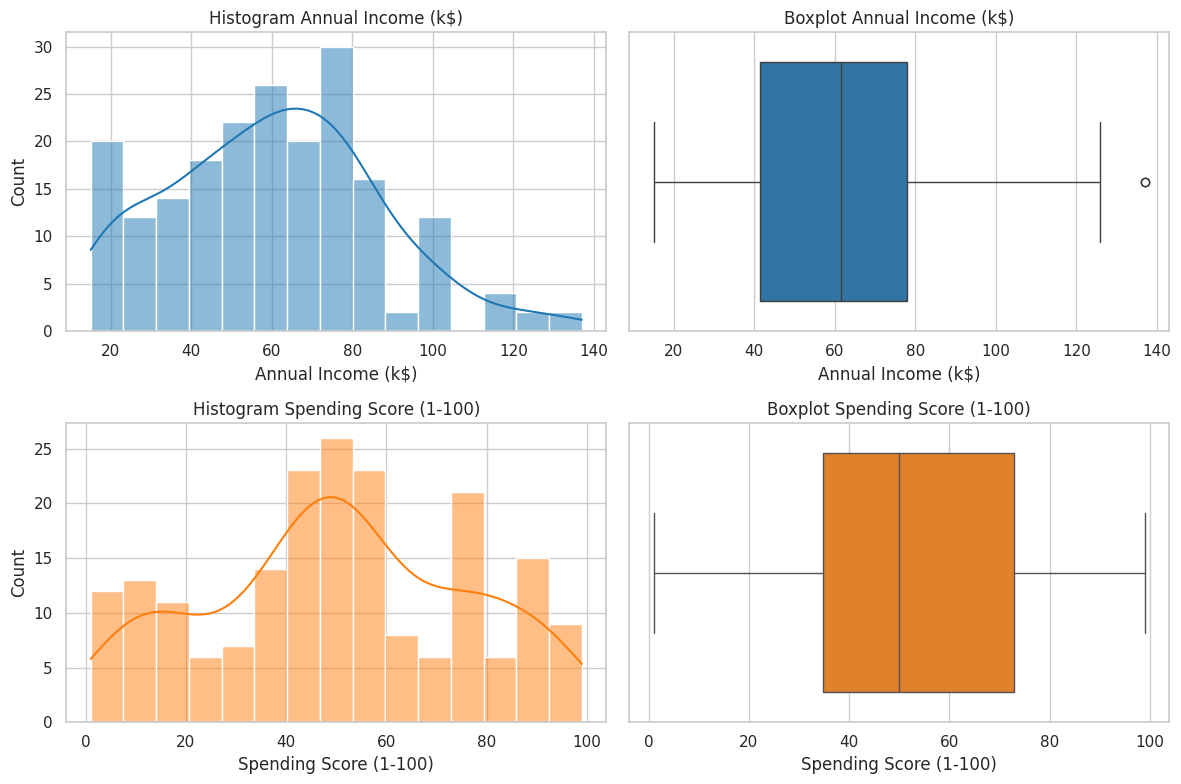

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[0, 0], color='tab:blue')
axes[0, 0].set_title('Histogram Annual Income (k$)')
sns.boxplot(x=df['Annual Income (k$)'], ax=axes[0, 1], color='tab:blue')
axes[0, 1].set_title('Boxplot Annual Income (k$)')

sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[1, 0], color='tab:orange')
axes[1, 0].set_title('Histogram Spending Score (1-100)')
sns.boxplot(x=df['Spending Score (1-100)'], ax=axes[1, 1], color='tab:orange')
axes[1, 1].set_title('Boxplot Spending Score (1-100)')

plt.tight_layout()
plt.show()

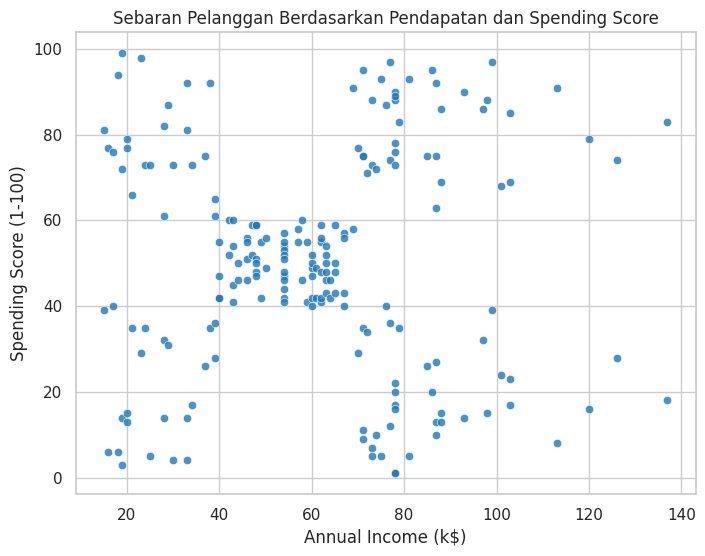

In [4]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', alpha=0.8)
plt.title('Sebaran Pelanggan Berdasarkan Pendapatan dan Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

## Pertanyaan EDA

- **Missing value dan duplikat:** dataset berisi 200 baris dan 5 kolom; tidak ada missing value maupun baris duplikat, sehingga tidak diperlukan penanganan khusus.
- **Rentang pendapatan dan spending score:** `Annual Income (k$)` berkisar 15–137 dengan rata-rata sekitar 60,6 dan median 61,5. `Spending Score (1-100)` berkisar 1–99 dengan rata-rata sekitar 50,2 dan median 50. Tidak terlihat outlier ekstrem pada boxplot, meskipun ada beberapa pelanggan berpendapatan sangat tinggi (di atas 120).
- **Kelompok yang terpisah:** pada scatter plot terlihat lima kelompok yang cukup jelas: pendapatan rendah–spending tinggi, pendapatan rendah–spending rendah, pendapatan menengah–spending menengah, pendapatan tinggi–spending tinggi, dan pendapatan tinggi–spending rendah. Struktur inilah yang akan dicoba ditemukan oleh ketiga algoritma.
- **Informasi tambahan:** `Age` berkisar 18–70 tahun (median 36) dan `Gender` terdiri dari 112 Female dan 88 Male. Keduanya tidak dipakai sebagai fitur utama, tetapi dapat membantu interpretasi cluster.

# 2. Preprocessing

In [5]:
print('Missing value sebelum preprocessing:')
print(df.isna().sum())
print('\nBaris duplikat sebelum preprocessing:', df.duplicated().sum())

# Dataset sudah bersih, jadi tidak ada baris yang perlu dihapus atau diimputasi.
# CustomerID adalah identitas sehingga tidak dimasukkan ke fitur clustering.
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

print('\nDimensi X:', X.shape)
display(X.head())

Missing value sebelum preprocessing:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Baris duplikat sebelum preprocessing: 0

Dimensi X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

display(X_scaled_df.head())
display(X_scaled_df.describe().round(3))

print('Rata-rata sebelum scaling:', scaler.mean_.round(2))
print('Standar deviasi sebelum scaling:', scaler.scale_.round(2))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


Rata-rata sebelum scaling: [60.56 50.2 ]
Standar deviasi sebelum scaling: [26.2  25.76]


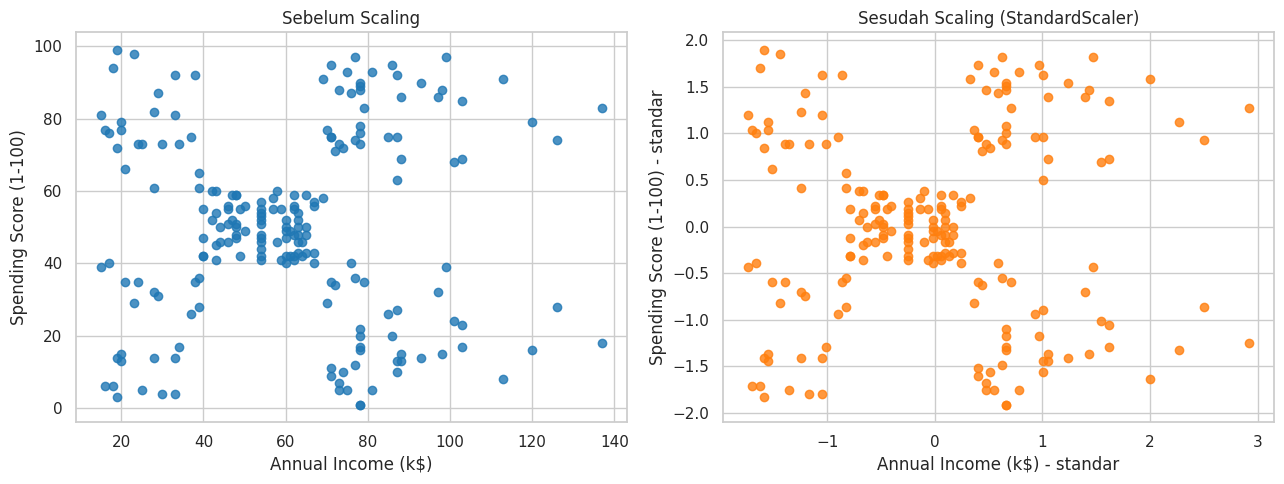

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], alpha=0.8)
axes[0].set_title('Sebelum Scaling')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')

axes[1].scatter(X_scaled_df['Annual Income (k$)'], X_scaled_df['Spending Score (1-100)'],
                alpha=0.8, color='tab:orange')
axes[1].set_title('Sesudah Scaling (StandardScaler)')
axes[1].set_xlabel('Annual Income (k$) - standar')
axes[1].set_ylabel('Spending Score (1-100) - standar')

plt.tight_layout()
plt.show()

**Mengapa scaling penting?** DBSCAN memakai jarak (`eps`), BIRCH memakai ambang jarak (`threshold`), dan GMM memakai matriks kovarians pada ruang fitur. Jika satuan fitur berbeda jauh, fitur dengan skala besar akan mendominasi perhitungan jarak. Pada dataset ini kedua fitur kebetulan memiliki simpangan baku yang mirip (sekitar 26,3 untuk pendapatan dan 25,8 untuk spending), sehingga bentuk sebaran sebelum dan sesudah scaling terlihat serupa; namun scaling tetap dilakukan agar kedua fitur diperlakukan setara dan agar `eps`/`threshold` dapat dibaca dalam satuan standar deviasi.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Alasannya, pendapatan menggambarkan kapasitas finansial pelanggan sedangkan spending score menggambarkan perilaku belanja. Kombinasi keduanya paling relevan untuk segmentasi pelanggan dan mudah divisualisasikan dalam dua dimensi. `CustomerID` tidak digunakan karena hanya identitas unik yang tidak memiliki makna jarak; jika dimasukkan, nilainya akan mendominasi perhitungan dan menghasilkan cluster yang tidak bermakna. `Gender` dan `Age` juga tidak dipakai pada eksperimen utama agar fokus pada dua fitur numerik, tetapi dapat dipakai untuk interpretasi tambahan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Eksperimen awal sesuai template: eps=0.3 dan min_samples=5.
dbscan_initial = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan_initial = dbscan_initial.fit_predict(X_scaled)
labels_dbscan = labels_dbscan_initial.copy()

print('DBSCAN awal dijalankan dengan eps=0.3 dan min_samples=5.')

DBSCAN awal dijalankan dengan eps=0.3 dan min_samples=5.


In [9]:
counts_dbscan = pd.Series(labels_dbscan).value_counts().sort_index()
print('Jumlah anggota per label:')
display(counts_dbscan.to_frame('jumlah'))

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = int((labels_dbscan == -1).sum())

print('Jumlah cluster (tanpa noise):', n_clusters_dbscan)
print('Jumlah noise (label -1):', n_noise_dbscan)
print(f'Persentase noise: {100 * n_noise_dbscan / len(labels_dbscan):.1f}%')

Jumlah anggota per label:


,jumlah
-1,35
0,12
1,5
2,7
3,88
4,30
5,14
6,9


Jumlah cluster (tanpa noise): 7
Jumlah noise (label -1): 35
Persentase noise: 17.5%


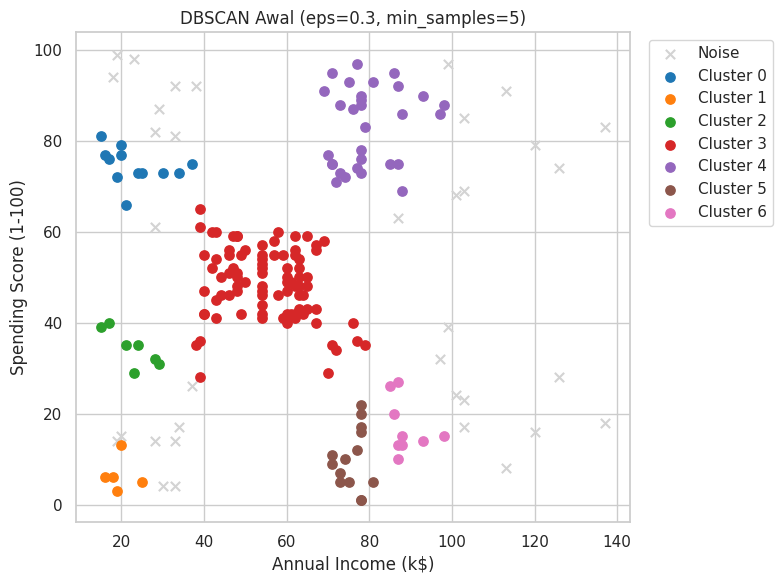

In [10]:
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_dbscan)):
    mask = labels_dbscan == label
    if label == -1:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                    c='lightgray', marker='x', s=45, label='Noise')
    else:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                    s=45, label=f'Cluster {label}')

plt.title('DBSCAN Awal (eps=0.3, min_samples=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [11]:
eps_values = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
min_samples_values = [3, 5, 8, 10]

rows = []
for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int((labels == -1).sum())
        n_non_noise = len(labels) - n_noise

        sil = np.nan
        if n_clusters >= 2 and n_clusters < n_non_noise:
            sil = silhouette_score(X_scaled[labels != -1], labels[labels != -1])

        rows.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_cluster': n_clusters,
            'noise': n_noise,
            'noise_%': round(100 * n_noise / len(labels), 1),
            'silhouette': sil,
        })

dbscan_grid = pd.DataFrame(rows)
display(dbscan_grid.round(4))

,eps,min_samples,n_cluster,noise,noise_%,silhouette
0,0.20,3,13,44,22.0,0.4697
1,0.20,5,7,77,38.5,0.5856
2,0.20,8,2,116,58.0,0.6027
3,0.20,10,1,129,64.5,NaN
4,0.25,3,12,16,8.0,0.4090
5,0.25,5,6,50,25.0,0.5317
6,0.25,8,5,79,39.5,0.5947
7,0.25,10,2,111,55.5,0.7287
8,0.30,3,9,14,7.0,0.4720
9,0.30,5,7,35,17.5,0.5243


### Analisis DBSCAN

- **Pengaruh `eps`:** semakin besar `eps`, radius lingkungan semakin luas sehingga cluster mudah bergabung dan jumlah cluster cenderung menurun. Pada `min_samples=5`, `eps=0.2` menghasilkan 7 cluster dengan 77 noise (38,5%), `eps=0.3` menghasilkan 7 cluster dengan 35 noise (17,5%), `eps=0.4` menghasilkan 4 cluster dengan 15 noise (7,5%), dan `eps=0.5` hanya menghasilkan 2 cluster dengan 8 noise (4%). Noise ikut menurun karena semakin banyak titik yang masuk radius tetangga.
- **Pengaruh `min_samples`:** semakin besar `min_samples`, syarat menjadi titik inti semakin ketat sehingga noise bertambah dan cluster menyusut/bergabung. Pada `eps=0.4`, `min_samples=3` menghasilkan 4 cluster dengan 10 noise, `min_samples=8` menghasilkan 5 cluster dengan 25 noise, dan `min_samples=10` menghasilkan 4 cluster dengan 51 noise (25,5%). Pada `eps=0.2, min_samples=10` bahkan hanya terbentuk 1 cluster dengan 129 noise, sehingga silhouette tidak valid.
- **Kondisi ekstrem:** `eps=0.2` dengan `min_samples` besar terlalu banyak membuang titik, sedangkan `eps=0.5` dengan `min_samples` kecil menggabungkan kelompok yang seharusnya terpisah menjadi hanya 2 cluster. Kombinasi yang dipilih adalah **`eps=0.45`, `min_samples=10`**: 5 cluster, 29 noise (14,5%), dan silhouette 0,5736. Nilai ini merupakan silhouette tertinggi di antara konfigurasi 5 cluster dengan noise di bawah 15%; noise sedikit lebih banyak daripada `eps=0.4, min_samples=8` (25 titik), tetapi kualitas pemisahan cluster lebih baik.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch_initial = Birch(threshold=0.5, n_clusters=5)
labels_birch_initial = birch_initial.fit_predict(X_scaled)
labels_birch = labels_birch_initial.copy()

print('BIRCH awal dijalankan dengan threshold=0.5 dan n_clusters=5.')

BIRCH awal dijalankan dengan threshold=0.5 dan n_clusters=5.


In [13]:
counts_birch = pd.Series(labels_birch).value_counts().sort_index()
print('Jumlah anggota per cluster:')
display(counts_birch.to_frame('jumlah'))
print('Jumlah cluster yang terbentuk:', len(set(labels_birch)))

Jumlah anggota per cluster:


,jumlah
0,36
1,109
2,8
3,25
4,22


Jumlah cluster yang terbentuk: 5


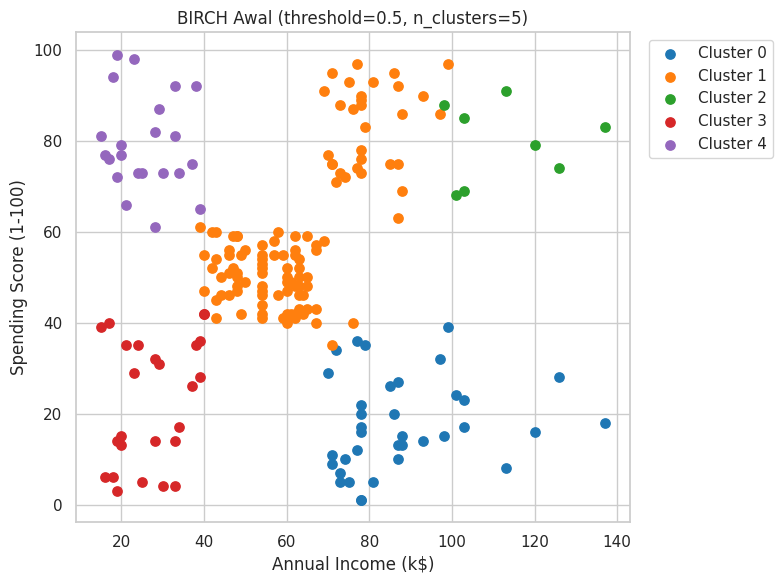

In [14]:
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_birch)):
    mask = labels_birch == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                s=45, label=f'Cluster {label}')

plt.title('BIRCH Awal (threshold=0.5, n_clusters=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [15]:
threshold_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]

rows = []
for threshold in threshold_values:
    model = Birch(threshold=threshold, n_clusters=5)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels))
    n_subclusters = model.subcluster_centers_.shape[0]

    sil = np.nan
    if 2 <= n_clusters < len(labels):
        sil = silhouette_score(X_scaled, labels)

    rows.append({
        'threshold': threshold,
        'n_subcluster': n_subclusters,
        'n_cluster': n_clusters,
        'silhouette': sil,
        'ukuran_cluster': np.bincount(labels).tolist(),
    })

birch_grid = pd.DataFrame(rows)
display(birch_grid.round(4))

/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/sklearn/cluster/_birch.py:730: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(
/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/sklearn/cluster/_birch.py:730: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_subcluster,n_cluster,silhouette,ukuran_cluster
0,0.2,39,5,0.5538,"[32, 23, 39, 21, 85]"
1,0.3,23,5,0.4781,"[101, 36, 38, 22, 3]"
2,0.4,15,5,0.5366,"[38, 26, 39, 21, 76]"
3,0.5,10,5,0.4145,"[36, 109, 8, 25, 22]"
4,0.6,8,5,0.4736,"[39, 104, 33, 20, 4]"
5,0.7,6,5,0.4207,"[96, 4, 32, 35, 33]"
6,0.8,4,4,0.4796,"[26, 97, 39, 38]"
7,1.0,4,4,0.3886,"[109, 30, 36, 25]"


In [16]:
rows = []
for threshold in [0.4, 0.5]:
    for n_clusters in [None, 5]:
        model = Birch(threshold=threshold, n_clusters=n_clusters)
        labels = model.fit_predict(X_scaled)
        rows.append({
            'threshold': threshold,
            'n_clusters': 'None' if n_clusters is None else n_clusters,
            'n_subcluster': model.subcluster_centers_.shape[0],
            'n_cluster_akhir': len(set(labels)),
            'silhouette': silhouette_score(X_scaled, labels),
        })

display(pd.DataFrame(rows).round(4))

,threshold,n_clusters,n_subcluster,n_cluster_akhir,silhouette
0,0.4,None,15,15,0.4143
1,0.4,5,15,5,0.5366
2,0.5,None,10,10,0.4774
3,0.5,5,10,5,0.4145


### Analisis BIRCH

- **Pengaruh `threshold`:** semakin besar `threshold`, titik yang lebih jauh masih boleh bergabung dalam satu subcluster, sehingga jumlah subcluster menurun drastis: 39 subcluster pada `threshold=0.2`, 23 pada 0.3, 15 pada 0.4, 10 pada 0.5, 6 pada 0.7, dan 4 pada 0.8–1.0. Selama jumlah subcluster masih ≥ 5, jumlah cluster akhir tetap 5 karena `n_clusters=5`. Ketika subcluster tinggal 4 (threshold 0.8 dan 1.0), BIRCH hanya dapat menghasilkan 4 cluster meskipun diminta 5.
- **Perbedaan dengan DBSCAN:** BIRCH memaksa setiap titik masuk ke cluster; titik yang jauh dari kelompok utama akan digabungkan ke cluster terdekat atau membentuk cluster kecil sendiri. DBSCAN justru memberi label noise pada titik tersebut. Pada data ini, BIRCH tidak menghasilkan label -1.
- **Pengaruh `n_clusters`:** pada `threshold=0.4`, tanpa `n_clusters` BIRCH menghasilkan 15 cluster dengan silhouette 0,4143; dengan `n_clusters=5` hasilnya 5 cluster dengan silhouette 0,5366. Namun pada `threshold=0.5`, tanpa `n_clusters` dihasilkan 10 cluster dengan silhouette 0,4774, sedangkan `n_clusters=5` menurunkannya menjadi 0,4145. Jadi penentuan `n_clusters` membantu merangkum subcluster menjadi jumlah yang diinginkan, tetapi tidak selalu menaikkan silhouette karena penggabungan paksa dapat mencampur kelompok yang berbeda.
- **Parameter terpilih:** **`threshold=0.4`, `n_clusters=5`**. Konfigurasi ini memberi 5 cluster yang seimbang (38, 26, 39, 21, 76 anggota) dan silhouette 0,5366, lebih baik daripada threshold awal 0.5 (0,4145). `threshold=0.2` memang sedikit lebih tinggi silhouette-nya (0,5538), tetapi membentuk 39 subcluster sehingga pohon ringkasannya lebih kompleks; `threshold=0.4` dipilih sebagai kompromi antara kualitas cluster dan kesederhanaan model.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [17]:
gmm_initial = GaussianMixture(
    n_components=5,
    covariance_type='full',
    random_state=RANDOM_STATE,
    n_init=10,
)
labels_gmm_initial = gmm_initial.fit_predict(X_scaled)
labels_gmm = labels_gmm_initial.copy()

print('GMM awal dijalankan dengan n_components=5, covariance_type=full, random_state=42.')

GMM awal dijalankan dengan n_components=5, covariance_type=full, random_state=42.


In [18]:
counts_gmm = pd.Series(labels_gmm).value_counts().sort_index()
print('Jumlah anggota per cluster:')
display(counts_gmm.to_frame('jumlah'))
print('Jumlah cluster yang terbentuk:', len(set(labels_gmm)))

proba_gmm = gmm_initial.predict_proba(X_scaled)
max_proba = proba_gmm.max(axis=1)

print('\nContoh probabilitas keanggotaan (5 baris pertama):')
display(pd.DataFrame(proba_gmm[:5], columns=[f'Komponen {i}' for i in range(5)]).round(3))

print('\nStatistik probabilitas maksimum per titik:')
print('Minimum :', round(max_proba.min(), 4))
print('Rata-rata:', round(max_proba.mean(), 4))
print('Median  :', round(np.median(max_proba), 4))
print('Jumlah titik dengan probabilitas maksimum < 0.6:', int((max_proba < 0.6).sum()))
print('Jumlah titik dengan probabilitas maksimum < 0.8:', int((max_proba < 0.8).sum()))

print('\nTitik yang paling tidak pasti:')
uncertain = np.argsort(max_proba)[:5]
display(pd.DataFrame({
    'index': uncertain,
    'Annual Income (k$)': df.loc[uncertain, 'Annual Income (k$)'].values,
    'Spending Score (1-100)': df.loc[uncertain, 'Spending Score (1-100)'].values,
    'cluster': labels_gmm[uncertain],
    'probabilitas_maks': max_proba[uncertain],
}).round(3))

Jumlah anggota per cluster:


,jumlah
0,21
1,33
2,39
3,23
4,84


Jumlah cluster yang terbentuk: 5

Contoh probabilitas keanggotaan (5 baris pertama):


,Komponen 0,Komponen 1,Komponen 2,Komponen 3,Komponen 4
0,0.001,0.0,0.0,0.999,0.0
1,1.000,0.0,0.0,0.000,0.0
2,0.000,0.0,0.0,1.000,0.0
3,1.000,0.0,0.0,0.000,0.0
4,0.002,0.0,0.0,0.998,0.0



Statistik probabilitas maksimum per titik:
Minimum : 0.5029
Rata-rata: 0.9827
Median  : 0.9996
Jumlah titik dengan probabilitas maksimum < 0.6: 1
Jumlah titik dengan probabilitas maksimum < 0.8: 6

Titik yang paling tidak pasti:


,index,Annual Income (k$),Spending Score (1-100),cluster,probabilitas_maks
0,124,70,29,1,0.503
1,48,40,42,4,0.611
2,49,40,42,4,0.611
3,27,28,61,0,0.675
4,160,79,35,4,0.772


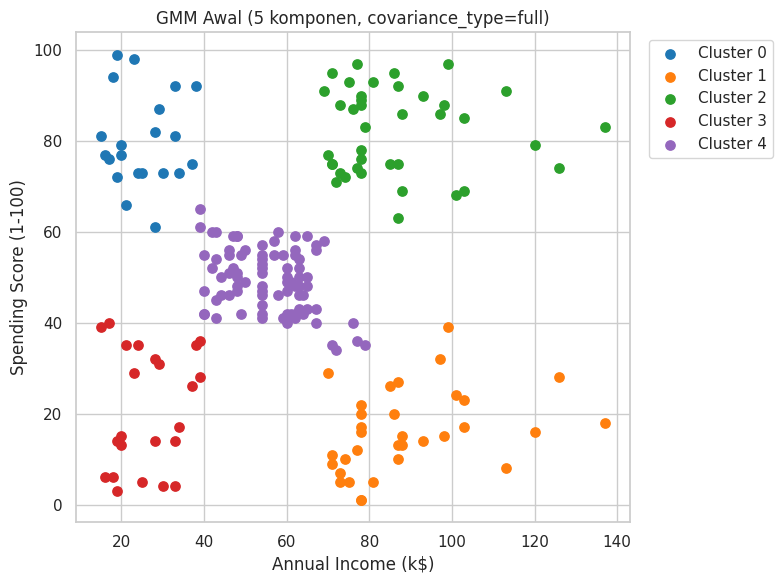

In [19]:
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_gmm)):
    mask = labels_gmm == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                s=45, label=f'Cluster {label}')

plt.title('GMM Awal (5 komponen, covariance_type=full)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [20]:
rows = []
for n_components in range(2, 9):
    model = GaussianMixture(
        n_components=n_components,
        covariance_type='full',
        random_state=RANDOM_STATE,
        n_init=10,
    )
    labels = model.fit_predict(X_scaled)
    rows.append({
        'n_components': n_components,
        'BIC': model.bic(X_scaled),
        'AIC': model.aic(X_scaled),
        'silhouette': silhouette_score(X_scaled, labels),
        'ukuran_cluster': np.bincount(labels).tolist(),
    })

gmm_grid = pd.DataFrame(rows)
display(gmm_grid.round(4))

print('BIC terendah pada n_components =', int(gmm_grid.loc[gmm_grid['BIC'].idxmin(), 'n_components']))
print('Silhouette tertinggi pada n_components =', int(gmm_grid.loc[gmm_grid['silhouette'].idxmax(), 'n_components']))

,n_components,BIC,AIC,silhouette,ukuran_cluster
0,2,1148.4725,1112.1910,0.3872,"[162, 38]"
1,3,1116.5015,1060.4301,0.3472,"[23, 42, 135]"
2,4,1079.4940,1003.6327,0.4509,"[25, 29, 107, 39]"
3,5,1058.6523,963.0010,0.5537,"[21, 33, 39, 23, 84]"
4,6,1071.5668,956.1257,0.5358,"[85, 32, 11, 23, 21, 28]"
5,7,1085.5904,950.3593,0.3852,"[19, 29, 39, 21, 67, 12, 13]"
6,8,1082.4804,927.4595,0.4651,"[21, 82, 19, 20, 23, 12, 15, 8]"


BIC terendah pada n_components = 5
Silhouette tertinggi pada n_components = 5


### Analisis EM/GMM

- **Arti probabilitas keanggotaan:** `predict_proba` menghasilkan probabilitas posterior setiap titik terhadap tiap komponen Gaussian. Label cluster diambil dari komponen dengan probabilitas terbesar. Probabilitas mendekati 1 berarti titik tersebut hampir pasti milik satu komponen, sedangkan probabilitas sekitar 0,5 menunjukkan titik berada di perbatasan dua komponen. Pada model awal, rata-rata probabilitas maksimum adalah 0,9827 dan hanya 1 titik yang probabilitas maksimumnya di bawah 0,6 (0,503), yaitu pelanggan dengan pendapatan 70k dan spending 29 yang hampir berimbang antara komponen high-income–low-spend dan komponen menengah. Titik dengan pendapatan 40k dan spending 42 juga relatif tidak pasti (0,611).
- **Peran EM:** langkah **E-step** menghitung tanggung jawab (responsibility) setiap titik terhadap setiap komponen berdasarkan parameter saat ini; langkah **M-step** memperbarui bobot campuran, mean, dan matriks kovarians menggunakan tanggung jawab tersebut. Kedua langkah diulang sampai log-likelihood konvergen.
- **Pengaruh `n_components`:** BIC menurun sampai 5 komponen (1058,65) lalu naik lagi pada 6–8 komponen, sedangkan silhouette tertinggi juga pada 5 komponen (0,5537). Dengan 2 komponen model terlalu sederhana (silhouette 0,3872), sedangkan 7 komponen mulai overfit (BIC 1085,59; silhouette 0,3852). Karena itu 5 komponen dipilih.
- **Mengapa jumlah cluster harus ditentukan lebih dulu:** GMM adalah model parametrik dengan jumlah komponen tetap; EM hanya mengestimasi parameter untuk jumlah komponen yang diberikan, bukan menemukan jumlah komponen secara otomatis. Pemilihan jumlah komponen dilakukan terpisah menggunakan BIC/AIC, silhouette, dan pertimbangan konteks.
- **Silhouette dan BIC:** untuk `covariance_type='full'`, keduanya menunjuk angka yang sama, yaitu 5 komponen. Ini memperkuat pilihan 5 cluster, meskipun BIC juga dipengaruhi bentuk kovarians dan jumlah parameter.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [21]:
def evaluate_clustering(X, labels, model_name):
    labels = np.asarray(labels)
    mask = labels != -1
    X_eval = X[mask]
    labels_eval = labels[mask]

    n_clusters = len(np.unique(labels_eval))
    n_noise = int((labels == -1).sum())
    n_eval = len(labels_eval)

    result = {
        'Model': model_name,
        'Jumlah Cluster': n_clusters,
        'Noise': n_noise,
        'Titik Dievaluasi': n_eval,
        'Silhouette': np.nan,
        'Davies-Bouldin': np.nan,
        'Calinski-Harabasz': np.nan,
    }

    if n_clusters >= 2 and n_clusters < n_eval:
        result['Silhouette'] = silhouette_score(X_eval, labels_eval)
        result['Davies-Bouldin'] = davies_bouldin_score(X_eval, labels_eval)
        result['Calinski-Harabasz'] = calinski_harabasz_score(X_eval, labels_eval)

    return result

In [22]:
# Tetapkan model terbaik dari eksperimen di atas.
dbscan_final = DBSCAN(eps=0.45, min_samples=10)
labels_dbscan = dbscan_final.fit_predict(X_scaled)

birch_final = Birch(threshold=0.4, n_clusters=5)
labels_birch = birch_final.fit_predict(X_scaled)

gmm_final = GaussianMixture(
    n_components=5,
    covariance_type='full',
    random_state=RANDOM_STATE,
    n_init=10,
)
labels_gmm = gmm_final.fit_predict(X_scaled)

hasil_evaluasi = pd.DataFrame([
    evaluate_clustering(X_scaled, labels_dbscan, 'DBSCAN (eps=0.45, min_samples=10)'),
    evaluate_clustering(X_scaled, labels_birch, 'BIRCH (threshold=0.4, n_clusters=5)'),
    evaluate_clustering(X_scaled, labels_gmm, 'GMM (5 komponen, full)'),
])

display(hasil_evaluasi.round(4))

,Model,Jumlah Cluster,Noise,Titik Dievaluasi,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,"DBSCAN (eps=0.45, min_samples=10)",5,29,171,0.5736,0.4830,245.1439
1,"BIRCH (threshold=0.4, n_clusters=5)",5,0,200,0.5366,0.5929,238.5513
2,"GMM (5 komponen, full)",5,0,200,0.5537,0.5760,244.9402


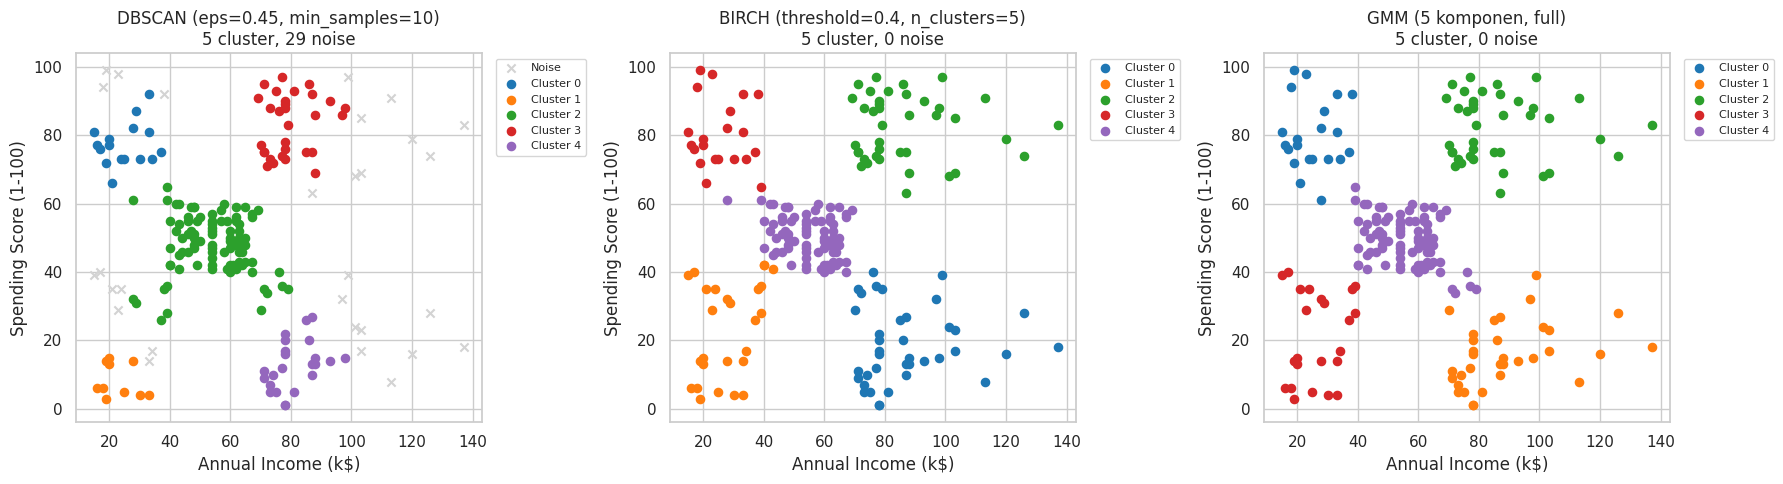

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ('DBSCAN (eps=0.45, min_samples=10)', labels_dbscan),
    ('BIRCH (threshold=0.4, n_clusters=5)', labels_birch),
    ('GMM (5 komponen, full)', labels_gmm),
]

for ax, (name, labels) in zip(axes, models):
    for label in sorted(set(labels)):
        mask = labels == label
        if label == -1:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                       c='lightgray', marker='x', s=35, label='Noise')
        else:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                       s=35, label=f'Cluster {label}')
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    ax.set_title(f'{name}\n{n_clusters} cluster, {n_noise} noise')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

In [24]:
def tampilkan_profil(labels, nama_model):
    tmp = df.copy()
    tmp['cluster'] = labels
    profil = tmp.groupby('cluster').agg(
        jumlah=('CustomerID', 'size'),
        income_median=('Annual Income (k$)', 'median'),
        income_mean=('Annual Income (k$)', 'mean'),
        spending_median=('Spending Score (1-100)', 'median'),
        spending_mean=('Spending Score (1-100)', 'mean'),
        age_median=('Age', 'median'),
        proporsi_male=('Gender', lambda s: (s == 'Male').mean()),
    ).round(2)
    profil.index = ['Noise (-1)' if i == -1 else f'Cluster {i}' for i in profil.index]
    print(f'\nProfil cluster {nama_model}:')
    display(profil)

tampilkan_profil(labels_dbscan, 'DBSCAN (eps=0.45, min_samples=10)')
tampilkan_profil(labels_birch, 'BIRCH (threshold=0.4, n_clusters=5)')
tampilkan_profil(labels_gmm, 'GMM (5 komponen, full)')


Profil cluster DBSCAN (eps=0.45, min_samples=10):


,jumlah,income_median,income_mean,spending_median,spending_mean,age_median,proporsi_male
Noise (-1),29,99.0,77.69,39.0,51.93,35.0,0.38
Cluster 0,16,24.5,25.06,76.5,77.31,22.5,0.44
Cluster 1,10,20.0,22.80,6.0,8.40,53.5,0.50
Cluster 2,92,54.0,54.15,48.5,48.10,45.5,0.39
Cluster 3,30,78.0,79.53,86.0,83.13,32.0,0.43
Cluster 4,23,78.0,80.96,13.0,12.78,43.0,0.70



Profil cluster BIRCH (threshold=0.4, n_clusters=5):


,jumlah,income_median,income_mean,spending_median,spending_mean,age_median,proporsi_male
Cluster 0,38,80.0,87.00,16.5,18.63,41.5,0.53
Cluster 1,26,28.0,28.00,27.0,23.31,45.5,0.38
Cluster 2,39,79.0,86.54,83.0,82.13,32.0,0.46
Cluster 3,21,24.0,25.62,77.0,80.24,23.0,0.38
Cluster 4,76,54.0,54.80,50.0,50.50,47.0,0.42



Profil cluster GMM (5 komponen, full):


,jumlah,income_median,income_mean,spending_median,spending_mean,age_median,proporsi_male
Cluster 0,21,24.0,25.10,77.0,80.05,23.0,0.43
Cluster 1,33,86.0,88.82,15.0,16.00,41.0,0.55
Cluster 2,39,79.0,86.54,83.0,82.13,32.0,0.46
Cluster 3,23,25.0,26.30,17.0,20.91,46.0,0.39
Cluster 4,84,55.5,55.64,49.5,49.37,46.5,0.40


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak, tetapi `eps` dan `min_samples` harus ditentukan | Ya, jika `n_clusters` diisi; bisa juga hanya memakai `threshold` | Ya, `n_components` harus ditentukan |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Mengikuti kepadatan, dapat tidak beraturan | Cenderung kompak/bola karena CF-tree | Elips sesuai matriks kovarians |
| Kelebihan | Deteksi noise, tidak perlu jumlah cluster, bentuk bebas | Cepat, hemat memori, cocok untuk data besar, bisa tanpa jumlah cluster | Keanggotaan probabilistik, bentuk elips, BIC/AIC untuk memilih jumlah komponen |
| Kekurangan | Sensitif parameter, sulit pada kepadatan bervariasi, noise dibuang dari analisis | Hasil bergantung threshold, sulit menangani noise, jumlah cluster bisa kurang dari `n_clusters` | Perlu jumlah komponen, asumsi Gaussian, dapat overfit |

# 7. Analisis

1. **Mengapa fitur perlu di-scaling?** Ketiga algoritma menggunakan jarak atau asumsi skala yang sebanding. DBSCAN memakai radius `eps`, BIRCH memakai `threshold` pada jarak, dan GMM memakai kovarians pada ruang fitur. Tanpa scaling, fitur dengan satuan/rentang lebih besar akan mendominasi jarak. Pada dataset ini rentang pendapatan (15–137) dan spending (1–99) cukup mirip dan simpangan bakunya juga mirip (26,26 vs 25,82), sehingga hasil sebelum dan sesudah scaling tidak berubah bentuk secara drastis. Meskipun demikian, scaling tetap penting agar `eps=0.45` dan `threshold=0.4` dapat ditafsirkan dalam satuan standar deviasi dan agar kedua fitur diberi bobot yang setara.
2. **Pengaruh parameter DBSCAN:** kenaikan `eps` memperbesar radius tetangga sehingga cluster bergabung dan jumlah cluster menurun, diikuti penurunan noise. Pada `min_samples=5`, `eps=0.2` memberi 7 cluster dan 77 noise, `eps=0.3` memberi 7 cluster dan 35 noise, `eps=0.4` memberi 4 cluster dan 15 noise, sedangkan `eps=0.5` hanya memberi 2 cluster dan 8 noise. Kenaikan `min_samples` membuat syarat core point lebih ketat: pada `eps=0.4`, `min_samples=3` menghasilkan 10 noise, `min_samples=8` menghasilkan 25 noise, dan `min_samples=10` menghasilkan 51 noise. Kombinasi ekstrem `eps=0.2, min_samples=10` menghasilkan satu cluster dengan 129 noise, sedangkan `eps=0.5` dengan `min_samples` kecil menggabungkan kelompok menjadi dua cluster besar. Konfigurasi terpilih `eps=0.45, min_samples=10` menghasilkan 5 cluster, 29 noise (14,5%), dan silhouette 0,5736.
3. **Pengaruh `threshold` dan `n_clusters` pada BIRCH:** kenaikan `threshold` menurunkan jumlah subcluster (39 → 23 → 15 → 10 → 8 → 6 → 4). Selama subcluster masih ≥ 5, jumlah cluster akhir tetap 5 karena `n_clusters=5`; ketika subcluster hanya 4 (threshold 0.8 dan 1.0), jumlah cluster akhir ikut menjadi 4. Tanpa `n_clusters`, BIRCH mengembalikan semua subcluster sebagai cluster (15 cluster pada threshold 0.4, 10 cluster pada threshold 0.5). Penentuan `n_clusters` menggabungkan subcluster menjadi jumlah yang diinginkan: pada threshold 0.4 silhouette naik dari 0,4143 menjadi 0,5366, tetapi pada threshold 0.5 silhouette justru turun dari 0,4774 menjadi 0,4145 karena penggabungan memaksa mencampur kelompok yang berbeda.
4. **Makna probabilitas GMM dan peran EM:** setiap titik memiliki probabilitas posterior terhadap tiap komponen. E-step menghitung tanggung jawab titik terhadap komponen, M-step memperbarui bobot, mean, dan kovarians, lalu iterasi berlanjut hingga log-likelihood konvergen. Pada model 5 komponen, rata-rata probabilitas maksimum 0,9827; hanya 1 titik di bawah 0,6 (0,503) dan 6 titik di bawah 0,8. Titik paling tidak pasti adalah pelanggan dengan pendapatan 70k dan spending 29 (0,503) serta pendapatan 40k dan spending 42 (0,611), yang memang berada di perbatasan segmen. Ketika `n_components` diubah, BIC minimum dan silhouette maksimum sama-sama terjadi pada 5 komponen; 2 komponen terlalu sederhana dan 7 komponen mulai overfit. Jumlah komponen harus ditentukan sebelum pelatihan karena GMM tidak mencari jumlah komponen sendiri.
5. **Model paling mudah diinterpretasikan:** GMM paling mudah dipakai untuk segmentasi karena seluruh 200 pelanggan mendapat label dan probabilitas keanggotaan, sehingga batas antar-segmen yang masih ambigu dapat diidentifikasi. Lima komponennya juga cocok dengan lima kelompok yang terlihat pada scatter plot. BIRCH memberikan hasil yang hampir sama dan lebih sederhana secara komputasi, tetapi hasilnya sensitif terhadap `threshold`. DBSCAN juga interpretatif untuk memisahkan pelanggan inti dari outlier, tetapi adanya label noise membuat sebagian pelanggan tidak masuk segmen mana pun.
6. **Apakah metrik menunjukkan pemenang yang sama?** Dengan konfigurasi terpilih, DBSCAN memiliki silhouette tertinggi (0,5736), Davies-Bouldin terendah (0,4830), dan Calinski-Harabasz tertinggi (245,1). Namun nilai tersebut dihitung hanya pada 171 titik non-noise; 29 titik (14,5%) dikeluarkan. Jika dibandingkan pada seluruh 200 titik, GMM lebih baik daripada BIRCH pada ketiga metrik (silhouette 0,5537 vs 0,5366; Davies-Bouldin 0,5760 vs 0,5929; Calinski-Harabasz 244,9 vs 238,6). Jadi metrik tidak selalu menunjuk pemenang yang sama tergantung apakah noise boleh dibuang, dan perbandingan DBSCAN dengan model lain tidak sepenuhnya apple-to-apple.
7. **Karakteristik dan nama cluster:** pola yang konsisten muncul pada ketiga model, yaitu:
   - **Pendapatan rendah–spending tinggi** (DBSCAN: 16 pelanggan, median 24,5k/76,5) → *impulsive spender*;
   - **Pendapatan rendah–spending rendah** (10 pelanggan, 20k/6) → *frugal/low-budget customer*;
   - **Pendapatan menengah–spending menengah** (92 pelanggan, 54k/48,5) → *standard customer*;
   - **Pendapatan tinggi–spending tinggi** (30 pelanggan, 78k/86) → *premium/target customer*;
   - **Pendapatan tinggi–spending rendah** (23 pelanggan, 78k/13) → *careful saver*.
   Noise DBSCAN (29 pelanggan, median 99k/39) terutama berisi pelanggan berpendapatan sangat tinggi dengan spending yang bervariasi, sehingga tidak masuk kepadatan lima segmen utama. Sebagai interpretasi tambahan, kelompok *impulsive* dan *premium* cenderung lebih muda (median usia sekitar 23 dan 32 tahun), sedangkan kelompok *frugal* dan *standard* lebih tua (median sekitar 54 dan 45 tahun); komposisi gender cukup seimbang (proporsi laki-laki 38–50%), kecuali kelompok *careful saver* yang sedikit lebih banyak laki-laki (70%), dan gender tidak dipakai dalam model.
8. **Keterbatasan dua fitur dan dataset kecil:** hanya memakai pendapatan dan spending berarti informasi usia, gender, frekuensi kunjungan, dan riwayat transaksi tidak diperhitungkan, sehingga segmen yang terbentuk belum tentu lengkap untuk strategi pemasaran. Dataset hanya 200 baris, sehingga hasil sensitif terhadap parameter, outlier, dan pembagian data; metrik internal juga tidak menjamin makna bisnis karena tidak ada label ground truth. DBSCAN membuang 14,5% data sebagai noise, GMM mengasumsikan komponen Gaussian berbentuk elips, dan BIRCH mengasumsikan cluster kompak. Validasi dengan data tambahan atau uji stabilitas (misalnya bootstrap) diperlukan sebelum hasil dipakai untuk keputusan nyata.

# 8. Kesimpulan dan Saran

- **Hasil paling berguna:** untuk segmentasi yang mencakup seluruh pelanggan, **GMM dengan 5 komponen dan `covariance_type='full'`** paling berguna karena memberikan silhouette 0,5537, Calinski-Harabasz 244,9, BIC terendah pada 5 komponen (1058,65), serta probabilitas keanggotaan yang memudahkan analisis pelanggan di batas segmen. Jika tujuan utamanya adalah menemukan pelanggan inti dan outlier, **DBSCAN `eps=0.45`, `min_samples=10`** lebih tepat: 5 cluster, 29 noise, silhouette 0,5736 pada titik non-noise, dan Davies-Bouldin 0,4830. **BIRCH `threshold=0.4`, `n_clusters=5`** menjadi alternatif cepat dengan hasil yang kompetitif (silhouette 0,5366).
- **Parameter yang dipilih dan alasannya:** DBSCAN memakai `eps=0.45` dan `min_samples=10` karena memberi 5 cluster dengan noise 14,5% dan silhouette tertinggi di antara konfigurasi 5 cluster dengan noise di bawah 15%. BIRCH memakai `threshold=0.4` dan `n_clusters=5` karena cluster seimbang dan silhouette lebih baik daripada threshold awal 0.5. GMM memakai 5 komponen, `covariance_type='full'`, `random_state=42`, dan `n_init=10` karena BIC minimum dan silhouette maksimum sama-sama tercapai pada 5 komponen.
- **Perbedaan utama:** DBSCAN berbasis kepadatan, tidak memerlukan jumlah cluster, dan dapat menandai noise; BIRCH merangkum data dalam CF-tree, cepat dan hemat memori, lalu menggabungkan subcluster; GMM/EM berbasis probabilitas, memerlukan jumlah komponen, dan memodelkan cluster sebagai distribusi Gaussian dengan bentuk elips. DBSCAN unggul untuk deteksi outlier, BIRCH unggul untuk efisiensi data besar, dan GMM unggul untuk keanggotaan probabilistik serta pemilihan model lewat BIC.
- **Saran eksperimen lanjutan:** tambahkan `Age` dan `Gender` (dengan encoding) atau fitur transaksi lain; bandingkan HDBSCAN/OPTICS untuk kepadatan yang bervariasi; uji stabilitas cluster dengan bootstrap atau beberapa `random_state`; coba `covariance_type='diag'`/`'tied'` pada GMM dan bandingkan BIC-nya; lakukan validasi segmen dengan data bisnis nyata, karena metrik internal hanya mengukur keterpisahan geometris, bukan nilai strategis segmen.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)